# 03 · Modelos sobre rasgos de forma

Pregunta P1: ¿cuánto explican los rasgos de forma por sí solos, qué grupos aportan a cada género, cuáles pueden confundir y cuánto agregan sobre el contenido?

| Sección | Modelo o análisis |
|---|---|
| 1 | **M2**: XGBoost con los 41 rasgos lingüísticos; control con los 4 rasgos de transcripción |
| 2 | Ablación por grupos: un solo grupo y todos menos uno |
| 3 | Importancia por permutación de grupos completos |
| 4 | Valores SHAP por género |
| 5 | Confusor temporal: ¿qué grupos predicen la época? |
| 6 | **M3**: aporte de los rasgos sobre las probabilidades del modelo TF-IDF (M1), con un cruce estricto sin fuga |

Todos los modelos usan las particiones de `data/processed/folds.parquet` (agrupadas por artista) y el protocolo de `src/evaluacion.py`. El early stopping de XGBoost usa una validación interna con artistas propios dentro del entrenamiento, nunca la partición de evaluación. Los hiperparámetros están fijos en la celda de configuración y no se ajustaron mirando resultados.

Requisitos: `python -m src.evaluacion` (particiones y M1) y `python -m src.rasgos` (rasgos). Tarda alrededor de 45 minutos en CPU, casi todo en la ablación.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src.datos import GENEROS, SEMILLA
from src.evaluacion import (K, TFIDF_REFERENCIA, bootstrap_artistas, cargar_folds, cargar_oof, comparar, cv_oof,
                            division_interna, etiquetas, f1_clases, guardar_oof, ic, macro_f1, particiones, predecir,
                            registrar)
from src.rasgos import GRUPOS, NOMBRE_GRUPO

PROC = RAIZ / "data" / "processed"
FIG = RAIZ / "reports" / "figures"
TAB = RAIZ / "reports" / "tablas"

pd.set_option("display.width", 180)
pd.set_option("display.float_format", "{:,.3f}".format)
NOMBRE = {"pop": "Pop", "rap": "Rap", "rock": "Rock", "rb": "R&B", "country": "Country"}
COLOR = {"pop": "#2a78d6", "rap": "#eb6834", "rock": "#1baf7a", "rb": "#eda100", "country": "#e87ba4"}
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 9, "axes.titlesize": 9.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2,
    "ytick.color": TINTA_2, "text.color": TINTA, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "font.family": "Arial",
})


def guardar(fig, nombre):
    fig.savefig(FIG / f"{nombre}.png", bbox_inches="tight", facecolor="white")


muestra = pd.read_parquet(PROC / "muestra.parquet", columns=["id", "tag", "artist", "year", "letra"])
R = pd.read_parquet(PROC / "rasgos.parquet").set_index("id").loc[muestra["id"]].reset_index(drop=True)
ids = muestra["id"].to_numpy()
Y = etiquetas(muestra["tag"])
artistas = muestra["artist"].to_numpy()
fold = cargar_folds(ids)
P_M0 = cargar_oof("M0_mayoritaria", ids)
P_M1 = cargar_oof("M1_tfidf_lr", ids)

LING = [c for g, cols in GRUPOS.items() if g != "T" for c in cols]   # 41 rasgos lingüísticos
G_LING = [g for g in GRUPOS if g != "T"]
print(f"{len(muestra):,} canciones; {len(LING)} rasgos lingüísticos + {len(GRUPOS['T'])} de transcripción")
print(f"M1 (TF-IDF + LR) sobre estas particiones: macro-F1 {macro_f1(Y, predecir(P_M1)):.3f}")

50,000 canciones; 41 rasgos lingüísticos + 4 de transcripción
M1 (TF-IDF + LR) sobre estas particiones: macro-F1 0.589


**Configuración de XGBoost.** Profundidad 6, tasa de aprendizaje 0,1, submuestreo de filas y columnas de 0,8 y hasta 2.000 árboles por clase, con early stopping de 50 rondas sobre la validación interna (15% de los artistas del entrenamiento). XGBoost acepta valores faltantes, así que las medidas de rima sin valor (letras con menos de tres pares de versos válidos) no se imputan.

In [2]:
PARAMS = dict(objective="multi:softprob", tree_method="hist", max_depth=6, learning_rate=0.1, subsample=0.8,
              colsample_bytree=0.8, min_child_weight=5, eval_metric="mlogloss", n_jobs=-1, random_state=SEMILLA)
MAX_ARBOLES, PARADA = 2000, 50


def ajustar_xgb(X, i_tr, y=Y, balancear=False):
    """XGBoost entrenado en i_tr, con early stopping sobre una validación interna de artistas propios."""
    i_fit, i_val = division_interna(i_tr, artistas)
    pesos = None
    if balancear:   # pesos inversos a la frecuencia de cada clase (para la época, que está desbalanceada)
        frec = np.bincount(y[i_tr]) / len(i_tr)
        pesos = 1 / (len(frec) * frec[y])
    m = xgb.XGBClassifier(**PARAMS, n_estimators=MAX_ARBOLES, early_stopping_rounds=PARADA)
    m.fit(X[i_fit], y[i_fit], eval_set=[(X[i_val], y[i_val])], verbose=False,
          sample_weight=None if pesos is None else pesos[i_fit],
          sample_weight_eval_set=None if pesos is None else [pesos[i_val]])
    return m


def con_xgb(columnas, modelos=None):
    """Interfaz de cv_oof para un XGBoost sobre las columnas indicadas de R."""
    X = R[columnas].to_numpy(dtype=np.float32)

    def entrenar_predecir(i_tr, i_te):
        m = ajustar_xgb(X, i_tr)
        if modelos is not None:
            modelos.append(m)
        return m.predict_proba(X[i_te])

    return entrenar_predecir


def correr(nombre, columnas, modelos=None, guardar_como=None, notas=""):
    t0 = time.time()
    P, f1s = cv_oof(con_xgb(columnas, modelos), Y, fold, nombre=nombre)
    if guardar_como:
        guardar_oof(guardar_como, ids, fold, P)
        registrar(guardar_como, f"rasgos ({len(columnas)})", {**PARAMS, "max_arboles": MAX_ARBOLES,
                  "parada": PARADA, "columnas": columnas}, f1s, time.time() - t0, notas)
    return P

## 1. M2: ¿cuánto explica la forma por sí sola?

Tres modelos con las mismas particiones: los 41 rasgos lingüísticos (M2), solo los 4 de transcripción (control) y ambos juntos. Los rasgos de transcripción no describen la canción sino cómo la escribió quien la transcribió en Genius; si por sí solos separan géneros, son un atajo como los encabezados (macro-F1 0,35 en el notebook 01) y no deben formar parte del modelo.

In [3]:
modelos_m2 = []
P_M2 = correr("M2 rasgos", LING, modelos_m2, "M2_xgb_rasgos")
P_T = correr("M2 transcripción", GRUPOS["T"], guardar_como="M2_xgb_transcripcion", notas="control: solo grupo T")
P_LT = correr("M2 rasgos + transcripción", LING + GRUPOS["T"])

tabla_m2 = comparar({"M0 mayoritaria": P_M0, "M1 TF-IDF + LR": P_M1, "M2 rasgos": P_M2,
                     "M2 transcripción (control)": P_T, "M2 rasgos + transcripción": P_LT},
                    Y, artistas, referencia="M2 rasgos")
tabla_m2.rename(columns=NOMBRE).to_csv(TAB / "m2_comparacion.csv")
tabla_m2.rename(columns=NOMBRE)

  M2 rasgos partición 0: macro-F1 0.557  (20 s)


  M2 rasgos partición 1: macro-F1 0.545  (45 s)


  M2 rasgos partición 2: macro-F1 0.543  (62 s)


  M2 rasgos partición 3: macro-F1 0.546  (79 s)


  M2 rasgos partición 4: macro-F1 0.555  (99 s)


M2 rasgos: macro-F1 0.549 ± 0.006 en 5 particiones


... (9 outputs left out)

  M2 rasgos + transcripción partición 3: macro-F1 0.555  (84 s)


  M2 rasgos + transcripción partición 4: macro-F1 0.560  (104 s)


M2 rasgos + transcripción: macro-F1 0.554 ± 0.006 en 5 particiones


,canciones,macro-F1,IC inf,IC sup,Pop,Rap,Rock,R&B,Country,Δ vs M2 rasgos,Δ IC inf,Δ IC sup
modelo,,,,,,,,,,,,
M0 mayoritaria,50000,0.067,0.064,0.070,0.000,0.000,0.000,0.000,0.333,-0.483,-0.488,-0.478
M1 TF-IDF + LR,50000,0.589,0.584,0.593,0.379,0.785,0.556,0.545,0.677,0.039,0.035,0.044
M2 rasgos,50000,0.549,0.544,0.554,0.347,0.777,0.510,0.497,0.614,NaN,NaN,NaN
M2 transcripción (control),50000,0.311,0.306,0.315,0.065,0.465,0.307,0.323,0.394,-0.238,-0.244,-0.233
M2 rasgos + transcripción,50000,0.554,0.549,0.559,0.351,0.776,0.515,0.504,0.622,0.004,0.002,0.007


## 2. Ablación por grupos

Para cada grupo se entrenan dos modelos: con **solo ese grupo** (cuánta información tiene por sí mismo) y con **todos menos ese grupo** (qué aporta que los demás no tengan). Se trabaja con grupos y no con rasgos sueltos porque los rasgos de un mismo grupo están correlacionados, y la importancia de cada uno por separado se subestima. Las diferencias se calculan sobre las mismas canciones y con los mismos remuestreos de artistas (IC 95%).

In [4]:
solo, sin = {}, {}
for g in G_LING:
    solo[g] = correr(f"solo {g}", GRUPOS[g])
    sin[g] = correr(f"sin {g}", [c for c in LING if c not in GRUPOS[g]])

preds = {"completo": predecir(P_M2)}
preds |= {f"solo {g}": predecir(solo[g]) for g in G_LING} | {f"sin {g}": predecir(sin[g]) for g in G_LING}
boot = bootstrap_artistas(preds, Y, artistas, n_boot=1000)

filas = []
for g in G_LING:
    f_solo, f_sin = f1_clases(Y, preds[f"solo {g}"]), f1_clases(Y, preds[f"sin {g}"])
    d = boot[f"sin {g}"] - boot["completo"]
    lo_s, hi_s = ic(boot[f"solo {g}"][:, K])
    lo_d, hi_d = ic(d[:, K])
    filas.append({"grupo": g, "nombre": NOMBRE_GRUPO[g], "rasgos": len(GRUPOS[g]),
                  "macro-F1 solo": f_solo.mean(), "solo IC inf": lo_s, "solo IC sup": hi_s,
                  "Δ macro-F1 al quitarlo": d[:, K].mean(), "Δ IC inf": lo_d, "Δ IC sup": hi_d,
                  **{f"Δ F1 {NOMBRE[x]}": d[:, k].mean() for k, x in enumerate(GENEROS)}})
ablacion = pd.DataFrame(filas).set_index("grupo")
ablacion.to_csv(TAB / "m2_ablacion_grupos.csv")
ablacion

  solo E partición 0: macro-F1 0.402  (3 s)


  solo E partición 1: macro-F1 0.400  (5 s)


  solo E partición 2: macro-F1 0.405  (8 s)


  solo E partición 3: macro-F1 0.400  (10 s)


  solo E partición 4: macro-F1 0.402  (12 s)


solo E: macro-F1 0.402 ± 0.002 en 5 particiones


... (87 outputs left out)

  sin X partición 3: macro-F1 0.543  (58 s)


  sin X partición 4: macro-F1 0.550  (72 s)


sin X: macro-F1 0.544 ± 0.007 en 5 particiones


,nombre,rasgos,macro-F1 solo,solo IC inf,solo IC sup,Δ macro-F1 al quitarlo,Δ IC inf,Δ IC sup,Δ F1 Pop,Δ F1 Rap,Δ F1 Rock,Δ F1 R&B,Δ F1 Country
grupo,,,,,,,,,,,,,
E,estructura,6,0.402,0.397,0.407,-0.011,-0.014,-0.007,0.000,-0.020,-0.008,-0.009,-0.015
R,repetición,4,0.365,0.360,0.369,-0.008,-0.011,-0.006,-0.013,-0.003,-0.001,-0.009,-0.015
S,rima y sonido,7,0.355,0.350,0.360,-0.007,-0.010,-0.004,0.003,-0.010,-0.009,-0.000,-0.017
M,métrica,3,0.347,0.342,0.352,-0.003,-0.005,0.000,0.001,-0.002,-0.001,-0.005,-0.006
D,diversidad léxica,4,0.352,0.347,0.356,-0.009,-0.012,-0.006,-0.003,-0.006,-0.004,-0.012,-0.018
P,pronombres,5,0.349,0.344,0.353,-0.009,-0.012,-0.005,0.003,-0.011,-0.005,-0.017,-0.011
O,oralidad y registro,6,0.426,0.421,0.431,-0.030,-0.034,-0.026,-0.013,-0.031,-0.050,-0.022,-0.034
X,sintaxis,6,0.335,0.330,0.339,-0.005,-0.008,-0.002,-0.004,-0.004,-0.003,-0.004,-0.010


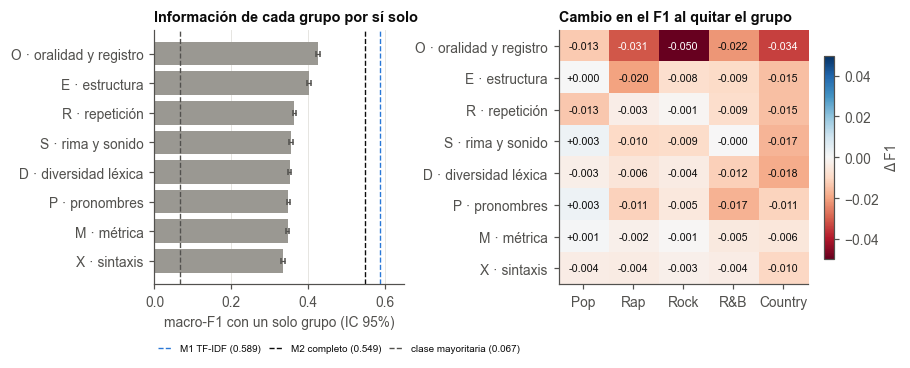

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(8.4, 3.0), gridspec_kw={"width_ratios": [1, 1.25], "wspace": 0.55})
orden = ablacion.sort_values("macro-F1 solo").index
etiq = [f"{g} · {NOMBRE_GRUPO[g]}" for g in orden]
a1.barh(etiq, ablacion.loc[orden, "macro-F1 solo"], color="#9a9892",
        xerr=[ablacion.loc[orden, "macro-F1 solo"] - ablacion.loc[orden, "solo IC inf"],
              ablacion.loc[orden, "solo IC sup"] - ablacion.loc[orden, "macro-F1 solo"]],
        capsize=2, error_kw={"lw": 0.8, "ecolor": TINTA_2})
for x, txt, c in [(macro_f1(Y, predecir(P_M1)), "M1 TF-IDF", "#2a78d6"), (macro_f1(Y, predecir(P_M2)), "M2 completo", TINTA),
                  (macro_f1(Y, predecir(P_M0)), "clase mayoritaria", TINTA_2)]:
    a1.axvline(x, color=c, lw=0.9, ls="--", label=f"{txt} ({x:.3f})")
a1.legend(loc="upper left", bbox_to_anchor=(-0.02, -0.2), ncol=3, fontsize=6.5, handlelength=1.4, columnspacing=0.8)
a1.set(xlabel="macro-F1 con un solo grupo (IC 95%)", xlim=(0, 0.65))
a1.set_title("Información de cada grupo por sí solo")
a1.grid(axis="y", visible=False)

delta = ablacion.loc[orden[::-1], [f"Δ F1 {NOMBRE[x]}" for x in GENEROS]].to_numpy()
lim = max(0.02, np.abs(delta).max())
im = a2.imshow(delta, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
a2.set_xticks(range(K), [NOMBRE[x] for x in GENEROS])
a2.set_yticks(range(len(orden)), etiq[::-1])
for i in range(delta.shape[0]):
    for j in range(K):
        a2.text(j, i, f"{delta[i, j]:+.3f}", ha="center", va="center", fontsize=7,
                color="white" if abs(delta[i, j]) > 0.6 * lim else TINTA)
a2.grid(False)
a2.set_title("Cambio en el F1 al quitar el grupo")
fig.colorbar(im, ax=a2, shrink=0.8, label="Δ F1")
guardar(fig, "m2_ablacion_grupos")

## 3. Importancia por permutación

Complemento de la ablación: en lugar de reentrenar, se toman los cinco modelos de M2 y, en cada partición de evaluación, se desordenan juntas todas las columnas de un grupo (tres repeticiones). La caída del macro-F1 mide cuánto **depende** el modelo entrenado de ese grupo. Puede diferir de la ablación: un grupo puede ser muy usado por el modelo y a la vez reemplazable por otros si se lo quita.

In [6]:
rng = np.random.default_rng(SEMILLA)
X_ling = R[LING].to_numpy(dtype=np.float32)
caidas = {g: [] for g in G_LING}
for m, (i_tr, i_te) in zip(modelos_m2, particiones(fold)):
    base = macro_f1(Y[i_te], m.predict_proba(X_ling[i_te]).argmax(1))
    for g in G_LING:
        cols = [LING.index(c) for c in GRUPOS[g]]
        for _ in range(3):
            Xp = X_ling[i_te].copy()
            Xp[:, cols] = Xp[rng.permutation(len(i_te))][:, cols]
            caidas[g].append(base - macro_f1(Y[i_te], m.predict_proba(Xp).argmax(1)))
permutacion = pd.DataFrame({"caída media de macro-F1": {g: np.mean(v) for g, v in caidas.items()},
                            "desvío": {g: np.std(v) for g, v in caidas.items()}})
permutacion.insert(0, "nombre", [NOMBRE_GRUPO[g] for g in permutacion.index])
permutacion["Δ al quitarlo (ablación)"] = -ablacion["Δ macro-F1 al quitarlo"]
permutacion.to_csv(TAB / "m2_permutacion_grupos.csv")
permutacion.sort_values("caída media de macro-F1", ascending=False)

,nombre,caída media de macro-F1,desvío,Δ al quitarlo (ablación)
O,oralidad y registro,0.113,0.004,0.030
E,estructura,0.063,0.005,0.011
D,diversidad léxica,0.037,0.003,0.009
P,pronombres,0.028,0.004,0.009
R,repetición,0.028,0.004,0.008
S,rima y sonido,0.017,0.002,0.007
X,sintaxis,0.017,0.003,0.005
M,métrica,0.008,0.002,0.003


## 4. Valores SHAP por género

XGBoost calcula de forma exacta la contribución de cada rasgo a la predicción de cada clase (TreeSHAP, `pred_contribs=True`). Se calculan sobre las canciones de evaluación de cada partición con el modelo que no las vio. Para cada género se informa la contribución absoluta media de cada rasgo y su **dirección**: la correlación de Spearman entre el valor del rasgo y su contribución hacia ese género (positiva: valores altos empujan hacia el género).

In [7]:
shap = np.zeros((len(Y), K, len(LING) + 1), dtype=np.float32)
for m, (_, i_te) in zip(modelos_m2, particiones(fold)):
    shap[i_te] = m.get_booster().predict(xgb.DMatrix(X_ling[i_te], missing=np.nan), pred_contribs=True)
shap = shap[:, :, :-1]   # la última columna es el término constante

importancia = pd.DataFrame(np.abs(shap).mean(0).T, index=LING, columns=[NOMBRE[g] for g in GENEROS])
direccion = pd.DataFrame({NOMBRE[g]: [pd.Series(X_ling[:, j]).corr(pd.Series(shap[:, k, j]), method="spearman")
                                      for j in range(len(LING))] for k, g in enumerate(GENEROS)}, index=LING)
importancia.to_csv(TAB / "m2_shap_importancia.csv")
direccion.to_csv(TAB / "m2_shap_direccion.csv")

filas = {}
for g in GENEROS:
    top = importancia[NOMBRE[g]].nlargest(5).index
    filas[NOMBRE[g]] = [f"{c} {'↑' if direccion.loc[c, NOMBRE[g]] > 0 else '↓'}" for c in top]
pd.DataFrame(filas, index=[f"{i}°" for i in range(1, 6)]).T.rename_axis("5 rasgos con más peso (↑ valores altos empujan hacia el género)")

,1°,2°,3°,4°,5°
5 rasgos con más peso (↑ valores altos empujan hacia el género),,,,,
Pop,o_groserias ↓,o_apocopes ↓,x_sustantivos ↓,e_versos_por_estrofa ↓,e_palabras_por_verso ↓
Rap,o_groserias ↑,o_cobertura_cmu ↓,e_versos_por_estrofa ↑,e_log_palabras ↑,s_densidad_asonancia ↑
Rock,o_coloquial ↓,e_log_palabras ↓,o_cobertura_cmu ↑,o_vocalizaciones ↓,o_apocopes ↓
R&B,p_tu ↑,d_mtld ↓,m_pct_acentuadas ↑,o_vocalizaciones ↑,p_yo ↑
Country,o_groserias ↓,o_cobertura_cmu ↑,d_mtld ↑,s_densidad_rima ↑,d_tipos_100 ↑


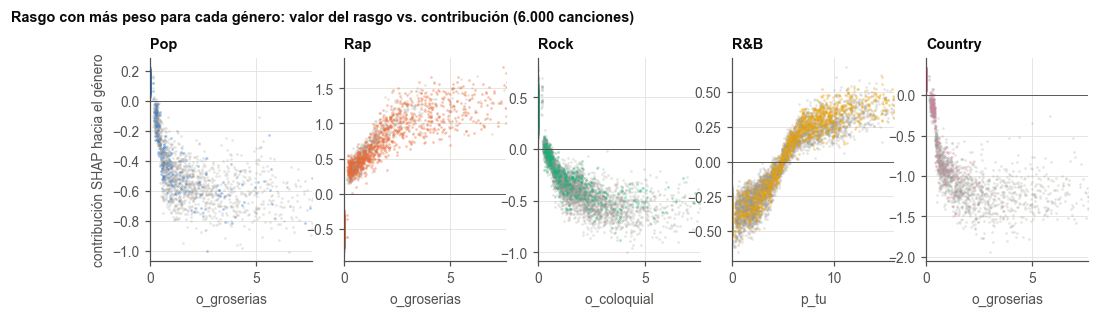

In [8]:
fig, ejes = plt.subplots(1, K, figsize=(11, 2.4), sharey=False)
sub = np.random.default_rng(SEMILLA).choice(len(Y), min(6000, len(Y)), replace=False)
for k, (g, ax) in enumerate(zip(GENEROS, ejes)):
    c = importancia[NOMBRE[g]].idxmax()
    j = LING.index(c)
    x, s = X_ling[sub, j], shap[sub, k, j]
    ok = ~np.isnan(x)
    lo, hi = np.nanpercentile(x, [1, 99])
    es_g = Y[sub][ok] == k
    ax.scatter(x[ok][~es_g], s[ok][~es_g], s=3, alpha=0.25, color="#9a9892", lw=0, label="otros géneros")
    ax.scatter(x[ok][es_g], s[ok][es_g], s=3, alpha=0.4, color=COLOR[g], lw=0, label=NOMBRE[g])
    ax.axhline(0, color=TINTA_2, lw=0.6)
    ax.set_xlim(lo, hi)
    ax.set(xlabel=c)
    ax.set_title(NOMBRE[g])
ejes[0].set_ylabel("contribución SHAP hacia el género")
fig.suptitle("Rasgo con más peso para cada género: valor del rasgo vs. contribución (6.000 canciones)", x=0.01,
             ha="left", fontsize=9.5, fontweight="bold", y=1.06)
guardar(fig, "m2_shap_dependencia")

## 5. Confusor temporal: ¿qué grupos predicen la época?

Un grupo es sospechoso si predice la época tan bien o mejor que el género. Se entrena un XGBoost por grupo para predecir el período (hasta 2009, 2010–2014, 2015–2022), con pesos que compensan el desbalance entre períodos, y se compara con la predicción del género del mismo grupo. Como las dos tareas tienen distinta cantidad de clases, se usa la exactitud balanceada normalizada: 0 equivale al azar y 1 a la clasificación perfecta.

In [9]:
anio = muestra["year"].where(muestra["year"].between(1900, 2022))
epoca = pd.cut(anio, [1899, 2009, 2014, 2022], labels=False)
con_anio = epoca.notna().to_numpy()
E = np.full(len(Y), -1)
E[con_anio] = epoca[con_anio].astype(int)


def norm_ba(y, p, k):
    return (balanced_accuracy_score(y, p) - 1 / k) / (1 - 1 / k)


def predecir_epoca(columnas):
    X = R[columnas].to_numpy(dtype=np.float32)
    pred = np.full(len(Y), -1)
    for i_tr, i_te in particiones(fold):
        i_tr, i_te = i_tr[con_anio[i_tr]], i_te[con_anio[i_te]]
        pred[i_te] = ajustar_xgb(X, i_tr, y=E, balancear=True).predict_proba(X[i_te]).argmax(1)
    return pred


pred_genero = {g: predecir(solo[g]) for g in G_LING} | {"T": predecir(P_T), "todos (41)": predecir(P_M2)}
columnas = {g: GRUPOS[g] for g in G_LING} | {"T": GRUPOS["T"], "todos (41)": LING}
filas = {}
for g, cols in columnas.items():
    pe = predecir_epoca(cols)
    filas[g] = {"nombre": NOMBRE_GRUPO.get(g, "todos los lingüísticos"),
                "género (BA normalizada)": norm_ba(Y[con_anio], pred_genero[g][con_anio], K),
                "época (BA normalizada)": norm_ba(E[con_anio], pe[con_anio], 3)}
temporal = pd.DataFrame(filas).T
temporal = temporal.astype({c: float for c in temporal.columns[1:]})
temporal["época / género"] = temporal["época (BA normalizada)"] / temporal["género (BA normalizada)"]
temporal.to_csv(TAB / "m2_confusor_temporal.csv")
temporal.sort_values("época / género", ascending=False)

,nombre,género (BA normalizada),época (BA normalizada),época / género
S,rima y sonido,0.211,0.144,0.683
M,métrica,0.199,0.128,0.643
todos (41),todos los lingüísticos,0.443,0.281,0.634
R,repetición,0.212,0.127,0.598
T,transcripción (control),0.173,0.103,0.595
X,sintaxis,0.187,0.108,0.577
D,diversidad léxica,0.198,0.112,0.567
O,oralidad y registro,0.296,0.162,0.547
P,pronombres,0.209,0.110,0.526
E,estructura,0.270,0.142,0.525


## 6. M3: ¿los rasgos agregan algo al contenido?

El aporte de la forma se mide con el mismo tipo de modelo y sobre las mismas canciones: un XGBoost de segundo nivel que recibe las probabilidades del modelo TF-IDF (M1), con y sin los rasgos lingüísticos. Comparar un modelo de árboles sobre la forma con una regresión logística sobre el contenido confundiría el efecto de los rasgos con el del tipo de modelo.

**Cruce estricto, sin fuga.** El segundo nivel se entrena con una mitad de los artistas y se evalúa en la otra. Para que la evaluación sea honesta, ninguna probabilidad de M1 usada para entrenar o evaluar el segundo nivel puede venir de un modelo que vio la mitad de evaluación. Las probabilidades fuera de muestra de las cinco particiones no cumplen esa condición: la de una canción de la mitad A la calculó un M1 entrenado con particiones que incluyen canciones de la mitad B. Por eso M1 se recalcula dentro de cada mitad:

1. Para evaluar en la mitad B, las probabilidades de M1 para las canciones de A se obtienen con una validación cruzada de cinco particiones agrupadas por artista hecha solo con canciones de A, y con ellas (más los rasgos) se entrena el segundo nivel.
2. Las probabilidades para las canciones de B las calcula un M1 entrenado con toda la mitad A.
3. Se repite intercambiando las mitades.

Como control, se agrega una variante con los rasgos de transcripción. La sección 6.2 compara este esquema con el que usa directamente las probabilidades de las cinco particiones.

In [10]:
mitad = np.empty(len(Y), dtype=int)
for h, (_, i_te) in enumerate(StratifiedGroupKFold(2, shuffle=True, random_state=SEMILLA).split(R, Y, artistas)):
    mitad[i_te] = h
letras = muestra["letra"]


def m1():
    """Clasificador de referencia M1, con la misma configuración que en src/evaluacion.py."""
    return make_pipeline(TfidfVectorizer(**TFIDF_REFERENCIA), LogisticRegression(max_iter=1000, C=4))


def m1_dentro_de(i_tr, i_te):
    """Probabilidades de M1 para i_tr (validación cruzada dentro de i_tr) y para i_te (M1 entrenado con todo i_tr)."""
    p_tr = np.zeros((len(i_tr), K))
    internas = StratifiedGroupKFold(5, shuffle=True, random_state=SEMILLA).split(i_tr, Y[i_tr], artistas[i_tr])
    for a, b in internas:
        p_tr[b] = m1().fit(letras.iloc[i_tr[a]], Y[i_tr[a]]).predict_proba(letras.iloc[i_tr[b]])
    p_te = m1().fit(letras.iloc[i_tr], Y[i_tr]).predict_proba(letras.iloc[i_te])
    return p_tr, p_te


def log_p(p):
    return np.log(np.clip(p, 1e-6, 1)).astype(np.float32)


t0 = time.time()
LOG_M1 = np.zeros((2, len(Y), K), dtype=np.float32)   # LOG_M1[h]: atributos del cruce que evalúa la mitad h
for h in (0, 1):
    i_tr, i_te = np.flatnonzero(mitad != h), np.flatnonzero(mitad == h)
    p_tr, p_te = m1_dentro_de(i_tr, i_te)
    LOG_M1[h, i_tr], LOG_M1[h, i_te] = log_p(p_tr), log_p(p_te)
    print(f"mitad {h}: M1 dentro de la otra mitad, macro-F1 {macro_f1(Y[i_te], p_te.argmax(1)):.3f}")
log_m1_cinco = log_p(P_M1)   # probabilidades de las cinco particiones (solo para el control de la sección 6.2)
print(f"M1 recalculado dentro de cada mitad: {time.time() - t0:.0f} s")

mitad 0: M1 dentro de la otra mitad, macro-F1 0.579


mitad 1: M1 dentro de la otra mitad, macro-F1 0.580
M1 recalculado dentro de cada mitad: 176 s


In [11]:
def cruce(extra, nombre, guardar_como, estricto=True):
    """XGBoost de segundo nivel sobre las log-probabilidades de M1 y `extra`, en el cruce de dos mitades.

    Con estricto=False usa las probabilidades fuera de muestra de las cinco particiones (control de la sección 6.2).
    """
    t0 = time.time()
    proba, f1s = np.full((len(Y), K), np.nan), []
    for h in (0, 1):
        i_tr, i_te = np.flatnonzero(mitad != h), np.flatnonzero(mitad == h)
        base = LOG_M1[h] if estricto else log_m1_cinco
        X = base if extra is None else np.hstack([base, extra])
        proba[i_te] = ajustar_xgb(X, i_tr).predict_proba(X[i_te])
        f1s.append(macro_f1(Y[i_te], predecir(proba[i_te])))
    print(f"{nombre}: macro-F1 {np.mean(f1s):.3f} ± {np.std(f1s):.3f} en 2 mitades ({time.time() - t0:.0f} s)")
    guardar_oof(guardar_como, ids, fold, proba)
    esquema = ("cruce 2× estricto: M1 recalculado dentro de cada mitad" if estricto
               else "control: cruce 2× sobre los OOF de M1 de las cinco particiones")
    registrar(guardar_como, nombre, {**PARAMS, "max_arboles": MAX_ARBOLES, "parada": PARADA}, np.array(f1s),
              time.time() - t0, esquema)
    return proba


def deltas_por_genero(P, P_ref):
    """Diferencia de F1 por género y de macro-F1 entre dos modelos, con IC 95% por bootstrap de artistas."""
    b = bootstrap_artistas({"m": predecir(P), "ref": predecir(P_ref)}, Y, artistas, n_boot=1000)
    d = b["m"] - b["ref"]
    lo, hi = ic(d)
    t = pd.DataFrame({"Δ F1": d.mean(0), "IC 95% inf": lo, "IC 95% sup": hi},
                     index=[NOMBRE[g] for g in GENEROS] + ["macro-F1"])
    t["¿excluye 0?"] = (t["IC 95% inf"] > 0) | (t["IC 95% sup"] < 0)
    return t


X_T = R[GRUPOS["T"]].to_numpy(np.float32)
P_M3c = cruce(None, "M3 contenido", "M3_xgb_contenido")
P_M3cr = cruce(X_ling, "M3 contenido + rasgos", "M3_xgb_contenido_rasgos")
P_M3crt = cruce(np.hstack([X_ling, X_T]), "M3 contenido + rasgos + transcripción", "M3_xgb_contenido_rasgos_transcripcion")

tabla_m3 = comparar({"M1 TF-IDF + LR": P_M1, "M3 contenido": P_M3c, "M3 contenido + rasgos": P_M3cr,
                     "M3 contenido + rasgos + transcripción": P_M3crt}, Y, artistas, referencia="M3 contenido")
tabla_m3.rename(columns=NOMBRE).to_csv(TAB / "m3_aporte_sobre_contenido.csv")
tabla_m3.rename(columns=NOMBRE)

M3 contenido: macro-F1 0.577 ± 0.001 en 2 mitades (4 s)


M3 contenido + rasgos: macro-F1 0.606 ± 0.001 en 2 mitades (20 s)


M3 contenido + rasgos + transcripción: macro-F1 0.608 ± 0.000 en 2 mitades (21 s)


,canciones,macro-F1,IC inf,IC sup,Pop,Rap,Rock,R&B,Country,Δ vs M3 contenido,Δ IC inf,Δ IC sup
modelo,,,,,,,,,,,,
M1 TF-IDF + LR,50000,0.589,0.584,0.593,0.379,0.785,0.556,0.545,0.677,0.012,0.008,0.015
M3 contenido,50000,0.577,0.572,0.582,0.339,0.777,0.556,0.544,0.668,NaN,NaN,NaN
M3 contenido + rasgos,50000,0.606,0.601,0.611,0.381,0.803,0.577,0.566,0.703,0.029,0.026,0.033
M3 contenido + rasgos + transcripción,50000,0.608,0.603,0.613,0.381,0.805,0.577,0.570,0.705,0.031,0.027,0.034


In [12]:
aporte = deltas_por_genero(P_M3cr, P_M3c)
aporte.to_csv(TAB / "m3_aporte_por_genero.csv")
aporte

,Δ F1,IC 95% inf,IC 95% sup,¿excluye 0?
Pop,0.042,0.033,0.052,True
Rap,0.026,0.022,0.030,True
Rock,0.021,0.014,0.027,True
R&B,0.022,0.016,0.028,True
Country,0.035,0.030,0.040,True
macro-F1,0.029,0.026,0.033,True


### 6.1 ¿Forma pura o estilo léxico?

Los valores SHAP (sección 4) muestran que las groserías son el rasgo de más peso para tres géneros. Pero las groserías y los marcadores coloquiales son listas de palabras, es decir, información que el TF-IDF también tiene. Para saber de dónde viene el aporte sobre el contenido, se repite M3 con dos subconjuntos: la **forma pura** (estructura, repetición, rima, métrica y diversidad léxica, que no miran qué palabras se usan) y el **estilo léxico** (pronombres, oralidad y sintaxis).

In [13]:
FORMA_PURA = [c for g in "ERSMD" for c in GRUPOS[g]]
ESTILO = [c for g in "POX" for c in GRUPOS[g]]
X_forma, X_estilo = R[FORMA_PURA].to_numpy(np.float32), R[ESTILO].to_numpy(np.float32)
P_M3cf = cruce(X_forma, "M3 contenido + forma pura", "M3_xgb_contenido_forma_pura")
P_M3ce = cruce(X_estilo, "M3 contenido + estilo léxico", "M3_xgb_contenido_estilo")

d_forma, d_estilo = deltas_por_genero(P_M3cf, P_M3c), deltas_por_genero(P_M3ce, P_M3c)


def con_ic(d):
    return (d["Δ F1"].map("{:+.3f}".format) + " [" + d["IC 95% inf"].map("{:+.3f}".format) + ", "
            + d["IC 95% sup"].map("{:+.3f}".format) + "]")


origen = pd.DataFrame({"forma pura (E, R, S, M, D)": con_ic(d_forma), "estilo léxico (P, O, X)": con_ic(d_estilo),
                       "todos los rasgos (41)": con_ic(aporte)}).rename_axis("Δ F1 sobre M3 contenido [IC 95%]")
origen.to_csv(TAB / "m3_forma_vs_estilo.csv")
origen

M3 contenido + forma pura: macro-F1 0.601 ± 0.000 en 2 mitades (13 s)


M3 contenido + estilo léxico: macro-F1 0.586 ± 0.002 en 2 mitades (10 s)


,"forma pura (E, R, S, M, D)","estilo léxico (P, O, X)",todos los rasgos (41)
Δ F1 sobre M3 contenido [IC 95%],,,
Pop,"+0.037 [+0.028, +0.045]","+0.015 [+0.007, +0.023]","+0.042 [+0.033, +0.052]"
Rap,"+0.022 [+0.018, +0.026]","+0.010 [+0.006, +0.013]","+0.026 [+0.022, +0.030]"
Rock,"+0.012 [+0.006, +0.018]","+0.011 [+0.006, +0.017]","+0.021 [+0.014, +0.027]"
R&B,"+0.019 [+0.013, +0.026]","+0.004 [-0.001, +0.009]","+0.022 [+0.016, +0.028]"
Country,"+0.029 [+0.024, +0.034]","+0.007 [+0.003, +0.011]","+0.035 [+0.030, +0.040]"
macro-F1,"+0.024 [+0.021, +0.027]","+0.009 [+0.006, +0.012]","+0.029 [+0.026, +0.033]"


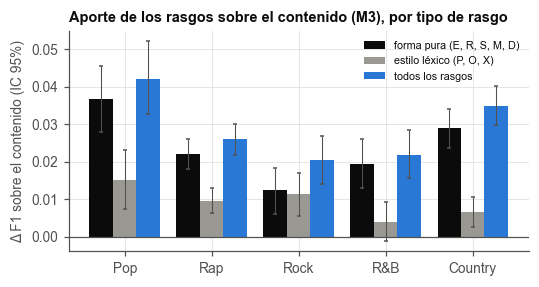

In [14]:
fig, ax = plt.subplots(figsize=(5.4, 2.6))
ancho = 0.27
for j, (d, etiqueta, color) in enumerate([(d_forma, "forma pura (E, R, S, M, D)", "#0b0b0b"),
                                          (d_estilo, "estilo léxico (P, O, X)", "#9a9892"),
                                          (aporte, "todos los rasgos", "#2a78d6")]):
    mu, lo, hi = d["Δ F1"].to_numpy()[:K], d["IC 95% inf"].to_numpy()[:K], d["IC 95% sup"].to_numpy()[:K]
    ax.bar(np.arange(K) + (j - 1) * ancho, mu, ancho, yerr=[mu - lo, hi - mu], color=color, label=etiqueta,
           capsize=1.5, error_kw={"lw": 0.7, "ecolor": TINTA_2})
ax.axhline(0, color=TINTA_2, lw=0.8)
ax.set_xticks(range(K), [NOMBRE[g] for g in GENEROS])
ax.set(ylabel="Δ F1 sobre el contenido (IC 95%)")
ax.set_title("Aporte de los rasgos sobre el contenido (M3), por tipo de rasgo")
ax.legend(fontsize=7, loc="upper right")
guardar(fig, "m3_aporte_por_genero")

### 6.2 Control: ¿cuánto cambia el resultado sin el cruce estricto?

Se repiten las cuatro variantes principales usando directamente las probabilidades fuera de muestra de las cinco particiones, que tienen la fuga descripta al comienzo de la sección 6. La diferencia de macro-F1 entre los dos esquemas mezcla dos efectos: la fuga y el tamaño de entrenamiento de M1, que en el cruce estricto se entrena con una mitad de las canciones (unas 20.000 a 25.000) y en las cinco particiones con 40.000. Lo comparable es el **aporte de los rasgos dentro de cada esquema** (Δ sobre "contenido"). Si ese aporte casi no cambia, la fuga no afecta la conclusión; de todos modos, las conclusiones se basan en el cruce estricto.

In [15]:
variantes = [("contenido", None, P_M3c), ("contenido + rasgos", X_ling, P_M3cr),
             ("contenido + forma pura", X_forma, P_M3cf), ("contenido + estilo léxico", X_estilo, P_M3ce)]
filas = {}
for nombre, extra, P_estricto in variantes:
    P_control = cruce(extra, f"M3 {nombre} (sin cruce estricto)", "M3_control_" + nombre.replace(" + ", "_")
                      .replace(" ", "_").replace("é", "e"), estricto=False)
    filas[nombre] = {"cruce estricto": macro_f1(Y, predecir(P_estricto)),
                     "sin cruce estricto": macro_f1(Y, predecir(P_control))}
control_fuga = pd.DataFrame(filas).T
control_fuga["diferencia"] = control_fuga["sin cruce estricto"] - control_fuga["cruce estricto"]
for esquema in ["cruce estricto", "sin cruce estricto"]:
    control_fuga[f"Δ sobre contenido ({esquema})"] = control_fuga[esquema] - control_fuga.loc["contenido", esquema]
control_fuga.to_csv(TAB / "m3_control_fuga.csv")
control_fuga.rename_axis("macro-F1 de M3")

M3 contenido (sin cruce estricto): macro-F1 0.587 ± 0.002 en 2 mitades (5 s)


M3 contenido + rasgos (sin cruce estricto): macro-F1 0.614 ± 0.001 en 2 mitades (18 s)


M3 contenido + forma pura (sin cruce estricto): macro-F1 0.608 ± 0.001 en 2 mitades (16 s)


M3 contenido + estilo léxico (sin cruce estricto): macro-F1 0.594 ± 0.002 en 2 mitades (12 s)


,cruce estricto,sin cruce estricto,diferencia,Δ sobre contenido (cruce estricto),Δ sobre contenido (sin cruce estricto)
macro-F1 de M3,,,,,
contenido,0.577,0.587,0.010,0.000,0.000
contenido + rasgos,0.606,0.614,0.008,0.029,0.028
contenido + forma pura,0.601,0.608,0.007,0.024,0.021
contenido + estilo léxico,0.586,0.594,0.008,0.009,0.007


## 7. Síntesis

| Modelo | Entrada | macro-F1 [IC 95%] |
|---|---|---|
| M1 | TF-IDF (100.000 términos) + LR | 0,589 [0,584; 0,593] |
| M2 | 41 rasgos lingüísticos | 0,549 [0,544; 0,554] |
| M2 (control) | 4 rasgos de transcripción | 0,311 [0,306; 0,315] |

| M3 (cruce estricto) | macro-F1 | Δ sobre M3 contenido [IC 95%] |
|---|---|---|
| probabilidades de M1 (contenido) | 0,577 | — |
| contenido + forma pura (E, R, S, M, D) | 0,601 | +0,024 [0,021; 0,027] |
| contenido + estilo léxico (P, O, X) | 0,586 | +0,009 [0,006; 0,012] |
| contenido + los 41 rasgos | 0,606 | +0,029 [0,026; 0,033] |

1. **La forma sola llega lejos.** 41 rasgos interpretables, sin vocabulario abierto, alcanzan 0,549: el 93% del macro-F1 del TF-IDF. En rap casi lo igualan (F1 0,777 contra 0,785).
2. **Atajo de transcripción.** Los cuatro rasgos de transcripción solos dan 0,311, un nivel parecido al de los encabezados (0,35). Agregan apenas +0,004 a los rasgos lingüísticos (M2) y +0,002 sobre contenido y rasgos (M3). Quedan fuera del modelo principal.
3. **Ablación.** Quitar cualquier grupo cuesta entre 0,003 y 0,011 de macro-F1, salvo oralidad y registro (−0,030): la información está repartida y es redundante entre grupos. Métrica es el único cuyo aporte no es significativo (IC [−0,005; 0,000]). Por género, la rima importa sobre todo para country (−0,017), luego para rap y rock (−0,010 y −0,009), y nada para pop y R&B. La repetición importa para country (−0,015) y pop (−0,013); los pronombres, para R&B (−0,017).
4. **Cómo decide el modelo (SHAP).** Las groserías son el rasgo de más peso para pop, rap y country: su presencia empuja hacia rap y su ausencia, hacia pop y country. Para R&B pesa la segunda persona ("you") y para rock, la ausencia de marcadores coloquiales. La densidad de rima perfecta está entre los cinco rasgos de más peso para country, y la asonancia, para rap.
5. **Confusor temporal.** Todos los grupos predicen el género mejor que la época (cociente época/género ≤ 0,68), así que ninguno queda marcado como confusor. El de mayor cociente es rima y sonido (0,68).
6. **Aporte sobre el contenido (respuesta a P1).** Con el mismo modelo, las mismas canciones y el cruce estricto, sumar los rasgos a las probabilidades del TF-IDF sube el macro-F1 de 0,577 a 0,606 (+0,029 [0,026; 0,033]), con mejora significativa en los cinco géneros. Más de cuatro quintas partes vienen de la **forma pura** (+0,024). El estilo léxico agrega poco (+0,009, no significativo en R&B): por sí solo es el grupo más fuerte, pero repite información que el TF-IDF ya tiene (groserías, jerga).
7. **Control de fuga (sección 6.2).** Con las probabilidades de las cinco particiones, que tienen fuga, el aporte de los rasgos es prácticamente el mismo (+0,028 frente a +0,029; forma pura +0,021 frente a +0,024), así que la fuga no cambia la conclusión. El nivel absoluto de M3 baja unas 0,01 con el cruce estricto porque M1 se entrena con la mitad de las canciones (macro-F1 0,58 en lugar de 0,589).
8. **Hipótesis de P1.**
   - Se confirma que la forma aporta en rap (+0,022 la forma pura).
   - Se refuta que rock y country se distingan casi solo por el contenido. La forma pura agrega +0,029 en country, el segundo mayor aporte, y +0,012 en rock, el menor.
   - El mayor aporte es en pop (+0,037 la forma pura; +0,042 con todos los rasgos), justamente el género con menos forma propia en el análisis univariado (notebook 02). Una explicación posible, a verificar en el análisis de error, es que la forma ayude a separarlo de rock y R&B, con los que más se confunde.

*Limitación:* el segundo nivel de M3 se entrena con la mitad de los artistas y, en el cruce estricto, M1 también. Por eso M3 contenido (0,577) queda por debajo de M1 (0,589), y la comparación válida es entre variantes de M3, no entre M3 y M1.